# 定量分析：ファイナリストと非ファイナリストの差の仮説検定

- 対象：都知事杯オープンデータ・ハッカソン 2026 の全提出作品 486 件（ファイナリスト 24 件・非ファイナリスト 462 件）
- 入力：`data/features.csv`（[`codebook.md`](codebook.md) の規則で機械付与した特徴量）、`data/manual_coding.csv`（手動コーディング 48 件）
- 出力：`data/hypothesis_tests.csv`、`data/hypothesis_tests_numeric.csv`、`reports/figures/fig01〜fig10_*.png`（分析 1 つにつき図を 1 枚以上）
- このノートブックは `scripts/build_notebook.py` から生成・実行している

## 検定の方針

| 項目 | 決めたこと |
|---|---|
| 帰無仮説 | 「その特徴の有無と、ファイナリストに選ばれるかどうかは無関係」 |
| 二値の特徴 | Fisher の正確検定（両側）。ファイナリストが 24 件と少なく、期待度数が 5 を下回るセルが多いため、カイ二乗検定は使わない |
| 効果の大きさ | オッズ比（条件付き最尤推定）と 95% 正確信頼区間 |
| 数値の特徴 | Mann-Whitney の U 検定（両側）。分布が歪んでいるため t 検定は使わない |
| 多カテゴリ（主テーマ・人数帯） | カイ二乗統計量の並べ替え検定（10 万回） |
| 有意水準 | 5% |
| 多重比較 | 16 個の仮説を同時に検定するので、Holm 法（厳しめ）と Benjamini-Hochberg 法（緩め）で補正した p 値も出す |
| 注意 | 仮説 H1〜H16 は、コードブックの観点から立てたが、**データを一度集計したあとに確定した**。厳密な意味での事前登録された検証ではなく、探索的な検定である |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.stats.contingency import odds_ratio

warnings.filterwarnings("ignore")
matplotlib.rcParams["font.family"] = ["Yu Gothic", "Meiryo", "MS Gothic", "sans-serif"]
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

df = pd.read_csv("data/features.csv", dtype={"id": str})
df["demo_own_domain"] = (df["demo_host"] == "独自ドメイン・その他").astype(int)
df["data_combine"] = (df["data_use_level"] == 3).astype(int)
df["data_show_only"] = (df["data_use_level"] == 1).astype(int)
df["sol_info"] = df["sol_情報提供・検索"]
df["word_route"] = df["title"].fillna("").str.contains("ルート").astype(int)
import json, glob, re
desc = {json.load(open(p, encoding="utf-8"))["id"]: json.load(open(p, encoding="utf-8"))["service_description"] or "" for p in glob.glob("data/details/*.json")}
df["word_route"] = df["id"].map(lambda i: int("ルート" in desc[i]) ) | df["word_route"]
y = df["is_finalist"].values
nF, nN = int(y.sum()), int((1 - y).sum())
print(f"全体 {len(df)} 件／ファイナリスト {nF} 件／非ファイナリスト {nN} 件／通過率 {nF/len(df):.1%}")

全体 486 件／ファイナリスト 24 件／非ファイナリスト 462 件／通過率 4.9%


In [2]:
import os
os.makedirs("reports/figures", exist_ok=True)
NL = chr(10)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e6e6"


def style(ax, grid_axis="x"):
    ax.grid(axis=grid_axis, color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#b5b5b5"); ax.spines["bottom"].set_color("#b5b5b5")
    ax.tick_params(colors=MUTED, length=0)


def save(fig, name):
    path = f"reports/figures/{name}.png"
    fig.savefig(path, dpi=150, facecolor="white"); print("保存:", path)

## 1. 仮説

| 番号 | 仮説（対立仮説） | 使う列 | 予想の向き |
|---|---|---|---|
| H1 | データを結合・計算して新しい指標を作る作品は通過しやすい | `data_use_level == 3` | ＋ |
| H2 | データを表示するだけの作品は通過しにくい | `data_use_level == 1` | − |
| H3 | デモ URL がある作品は通過しやすい | `has_demo` | ＋ |
| H4 | デモを独自ドメイン等で公開している作品は通過しやすい | `demo_host` | ＋ |
| H5 | 3D・AR・PLATEAU を使う作品は通過しやすい | `tech_3d_ar` | ＋ |
| H6 | 機械学習・最適化・シミュレーションを使う作品は通過しやすい | `tech_ml` | ＋ |
| H7 | AI が機能として動く作品は通過しやすい | `ai_in_product` | ＋ |
| H8 | 地図・GIS を使う作品は通過しやすい | `tech_map` | ＋ |
| H9 | 特定の対象者（高齢者・障害者・外国人・子育て・子ども）を持つ作品は通過しやすい | `user_specific` | ＋ |
| H10 | 課題の説明に数字の根拠がある作品は通過しやすい | `problem_number` | ＋ |
| H11 | 行政の制度・施策に言及する作品は通過しやすい | `desc_policy` | ＋ |
| H12 | 都のデータと都以外のデータを併用する作品は通過しやすい | `data_cross` | ＋ |
| H13 | 都のデータを 1 つも使わない作品は通過しにくい | `data_no_tokyo` | − |
| H14 | 1 人チームは通過しにくい | `solo` | − |
| H15 | 情報提供・検索型の作品は通過しにくい | `sol_情報提供・検索` | − |
| H16 | 「ルート」を扱う作品は通過しにくい | 本文・題名に「ルート」 | − |

In [3]:
H = [
    ("H1", "データを結合・計算して新しい指標を作る", "data_combine", "+"),
    ("H2", "データを表示するだけ", "data_show_only", "-"),
    ("H3", "デモ URL あり", "has_demo", "+"),
    ("H4", "デモが独自ドメイン等", "demo_own_domain", "+"),
    ("H5", "3D・AR・PLATEAU", "tech_3d_ar", "+"),
    ("H6", "機械学習・最適化・シミュレーション", "tech_ml", "+"),
    ("H7", "AI が機能として動く", "ai_in_product", "+"),
    ("H8", "地図・GIS", "tech_map", "+"),
    ("H9", "特定の対象者あり", "user_specific", "+"),
    ("H10", "課題の説明に数字の根拠", "problem_number", "+"),
    ("H11", "行政の制度・施策への言及", "desc_policy", "+"),
    ("H12", "都データと都以外データの併用", "data_cross", "+"),
    ("H13", "都のデータ 0 件", "data_no_tokyo", "-"),
    ("H14", "1 人チーム", "solo", "-"),
    ("H15", "情報提供・検索型", "sol_info", "-"),
    ("H16", "「ルート」を扱う", "word_route", "-"),
]


def holm(p):
    p = np.asarray(p); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1, run)
    return adj


def bh(p):
    p = np.asarray(p); m = len(p); order = np.argsort(p)[::-1]; adj = np.empty(m); run = 1
    for k, i in enumerate(order):
        rank = m - k; run = min(run, p[i] * m / rank); adj[i] = run
    return adj


rows = []
for hid, label, col, sign in H:
    x = df[col].values
    a, b = int(((x == 1) & (y == 1)).sum()), int(((x == 0) & (y == 1)).sum())
    c, d = int(((x == 1) & (y == 0)).sum()), int(((x == 0) & (y == 0)).sum())
    p = stats.fisher_exact([[a, b], [c, d]], alternative="two-sided")[1]
    orr = odds_ratio([[a, b], [c, d]])
    lo, hi = orr.confidence_interval(0.95)
    rows.append(dict(仮説=hid, 特徴=label, 予想=sign, F該当=a, F総数=nF, N該当=c, N総数=nN,
                     F割合=a / nF, N割合=c / nN, 通過率_該当=a / (a + c) if a + c else np.nan,
                     通過率_非該当=b / (b + d), オッズ比=orr.statistic, CI下限=lo, CI上限=hi, p値=p))
T = pd.DataFrame(rows)
T["p_Holm"] = holm(T["p値"]); T["p_BH"] = bh(T["p値"])
T["向き"] = np.where(T["オッズ比"] > 1, "+", "-")
T["予想と一致"] = np.where(T["向き"] == T["予想"], "○", "×")
T["判定"] = np.select([T["p_Holm"] < 0.05, T["p値"] < 0.05], ["補正後も有意", "補正前のみ有意"], "有意でない")
T.to_csv("data/hypothesis_tests.csv", index=False, encoding="utf-8-sig")
show = T.copy()
for c in ["F割合", "N割合", "通過率_該当", "通過率_非該当"]:
    show[c] = (show[c] * 100).round(1).astype(str) + "%"
for c in ["オッズ比", "CI下限", "CI上限"]:
    show[c] = show[c].round(2)
for c in ["p値", "p_Holm", "p_BH"]:
    show[c] = show[c].round(3)
show[["仮説", "特徴", "F該当", "N該当", "F割合", "N割合", "通過率_該当", "通過率_非該当", "オッズ比", "CI下限", "CI上限", "p値", "p_Holm", "p_BH", "予想と一致", "判定"]]

,仮説,特徴,F該当,N該当,F割合,N割合,通過率_該当,通過率_非該当,オッズ比,CI下限,CI上限,p値,p_Holm,p_BH,予想と一致,判定
0,H1,データを結合・計算して新しい指標を作る,15,189,62.5%,40.9%,7.4%,3.2%,2.40,0.96,6.37,0.054,0.705,0.217,○,有意でない
1,H2,データを表示するだけ,5,163,20.8%,35.3%,3.0%,6.0%,0.48,0.14,1.37,0.188,1.000,0.501,○,有意でない
2,H3,デモ URL あり,19,313,79.2%,67.7%,5.7%,3.2%,1.81,0.64,6.31,0.271,1.000,0.563,○,有意でない
3,H4,デモが独自ドメイン等,6,48,25.0%,10.4%,11.1%,4.2%,2.87,0.89,8.01,0.039,0.550,0.210,○,補正前のみ有意
4,H5,3D・AR・PLATEAU,5,32,20.8%,6.9%,13.5%,4.2%,3.52,0.96,10.63,0.028,0.454,0.210,○,補正前のみ有意
5,H6,機械学習・最適化・シミュレーション,5,33,20.8%,7.1%,13.2%,4.2%,3.41,0.93,10.26,0.032,0.473,0.210,○,補正前のみ有意
6,H7,AI が機能として動く,12,174,50.0%,37.7%,6.5%,4.0%,1.65,0.66,4.12,0.282,1.000,0.563,○,有意でない
7,H8,地図・GIS,8,183,33.3%,39.6%,4.2%,5.4%,0.76,0.28,1.94,0.670,1.000,0.835,×,有意でない
8,H9,特定の対象者あり,7,177,29.2%,38.3%,3.8%,5.6%,0.66,0.23,1.72,0.399,1.000,0.639,×,有意でない
9,H10,課題の説明に数字の根拠,8,145,33.3%,31.4%,5.2%,4.8%,1.09,0.40,2.78,0.825,1.000,0.835,○,有意でない


## 2. 二値の特徴：Fisher の正確検定

上の表が結果。読み方：

- **オッズ比** が 1 より大きければ、その特徴を持つ作品のほうが通過しやすい。95% 信頼区間が 1 をまたぐなら、「差がある」とは言えない
- **p 値** は補正前。**p_Holm** は 16 個を同時に検定したことを踏まえた補正後の値

保存: reports/figures/fig01_feature_rates.png


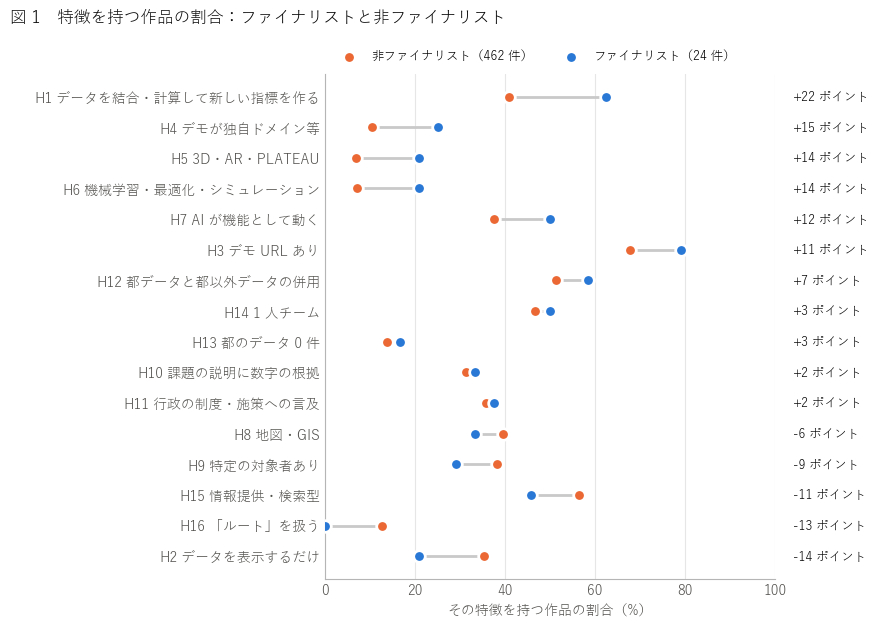

In [4]:
# 図 1: 16 仮説それぞれの「その特徴を持つ作品の割合」を 2 群で比べる
o = T.assign(diff=T["F割合"] - T["N割合"]).sort_values("diff")
fig, ax = plt.subplots(figsize=(9, 6.4)); yp = np.arange(len(o))
ax.hlines(yp, o["N割合"] * 100, o["F割合"] * 100, color="#c9c9c9", lw=2, zorder=1)
ax.scatter(o["N割合"] * 100, yp, s=70, color=ORANGE, edgecolor="white", linewidth=2, zorder=3, label="非ファイナリスト（462 件）")
ax.scatter(o["F割合"] * 100, yp, s=70, color=BLUE, edgecolor="white", linewidth=2, zorder=3, label="ファイナリスト（24 件）")
ax.set_yticks(yp); ax.set_yticklabels([f"{h} {l}" for h, l in zip(o["仮説"], o["特徴"])], color=INK)
for yy, (_, r) in zip(yp, o.iterrows()):
    ax.text(104, yy, f"{r['diff'] * 100:+.0f} ポイント", va="center", fontsize=9, color=INK, clip_on=False)
ax.set_xlim(0, 100); ax.set_xlabel("その特徴を持つ作品の割合（%）", color=MUTED)
fig.suptitle("図 1　特徴を持つ作品の割合：ファイナリストと非ファイナリスト", x=0.01, ha="left", color=INK, fontsize=12)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9); style(ax)
fig.subplots_adjust(left=0.36, right=0.86, bottom=0.09, top=0.88); save(fig, "fig01_feature_rates"); plt.show()

保存: reports/figures/fig02_odds_ratio.png


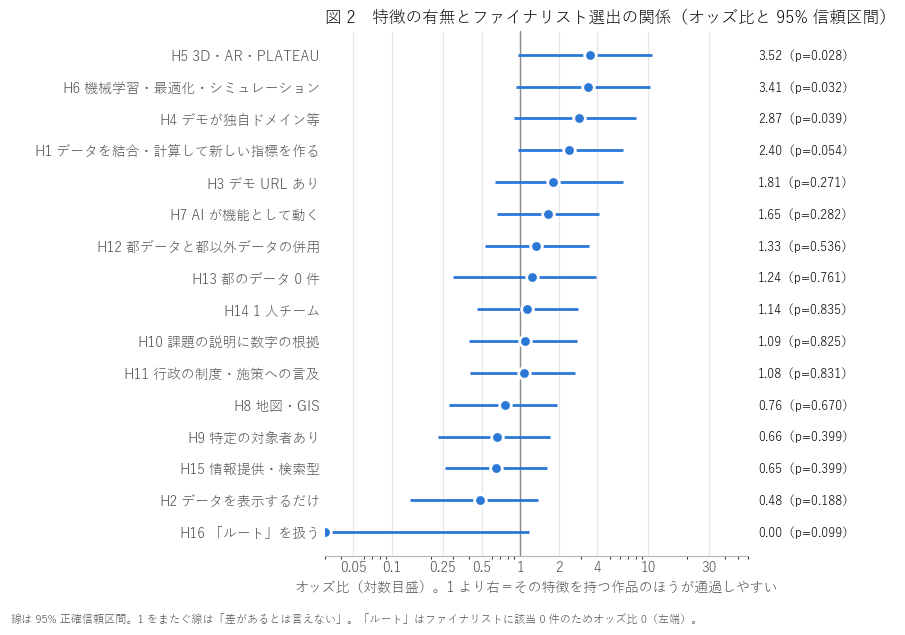

In [5]:
# 図 2: オッズ比と 95% 信頼区間
order = T.sort_values("オッズ比")
fig, ax = plt.subplots(figsize=(9, 6.4)); ypos = np.arange(len(order))
orv = order["オッズ比"].clip(lower=0.03).values; lo = order["CI下限"].clip(lower=0.03).values; hi = order["CI上限"].clip(upper=60).values
ax.hlines(ypos, lo, hi, color=BLUE, lw=2, zorder=2)
ax.scatter(orv, ypos, s=70, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
ax.axvline(1, color="#8a8a8a", lw=1, zorder=1)
ax.set_xscale("log"); ax.set_xlim(0.03, 60)
ax.set_xticks([0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10, 30]); ax.set_xticklabels(["0.05", "0.1", "0.25", "0.5", "1", "2", "4", "10", "30"])
ax.set_yticks(ypos); ax.set_yticklabels([f"{h} {l}" for h, l in zip(order["仮説"], order["特徴"])], color=INK)
for yy, (_, r) in zip(ypos, order.iterrows()):
    ax.text(72, yy, f"{r['オッズ比']:.2f}（p={r['p値']:.3f}）", va="center", ha="left", fontsize=9, color=INK, clip_on=False)
ax.set_xlabel("オッズ比（対数目盛）。1 より右＝その特徴を持つ作品のほうが通過しやすい", color=MUTED)
ax.set_title("図 2　特徴の有無とファイナリスト選出の関係（オッズ比と 95% 信頼区間）", loc="left", color=INK, fontsize=12)
style(ax); ax.spines["left"].set_visible(False)
fig.text(0.01, 0.005, "線は 95% 正確信頼区間。1 をまたぐ線は「差があるとは言えない」。「ルート」はファイナリストに該当 0 件のためオッズ比 0（左端）。", fontsize=8, color=MUTED)
fig.subplots_adjust(left=0.36, right=0.83, bottom=0.11, top=0.93); save(fig, "fig02_odds_ratio"); plt.show()

保存: reports/figures/fig03_pvalues_correction.png


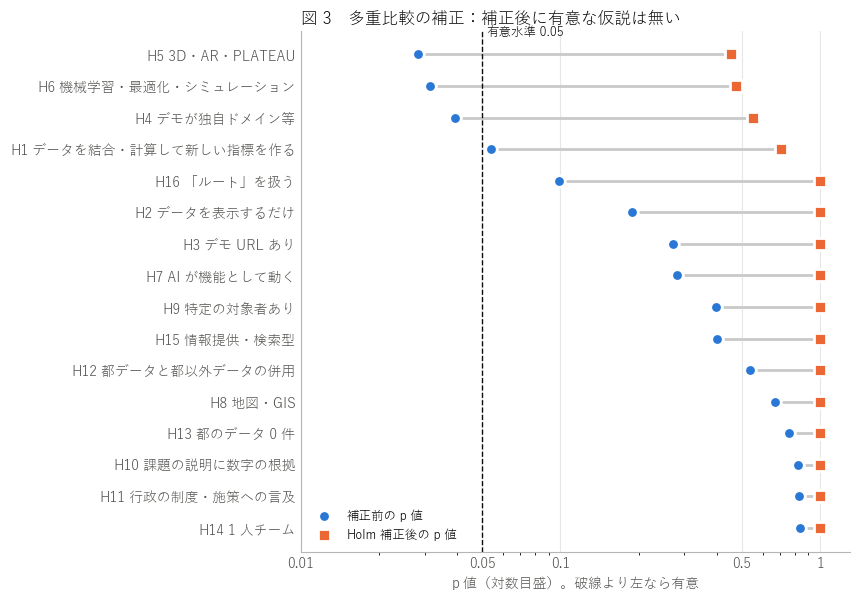

In [6]:
# 図 3: p 値（補正前）と多重比較の補正後
o = T.sort_values("p値", ascending=False); yp = np.arange(len(o))
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.hlines(yp, o["p値"], o["p_Holm"], color="#c9c9c9", lw=2, zorder=1)
ax.scatter(o["p値"], yp, s=70, color=BLUE, edgecolor="white", linewidth=2, zorder=3, label="補正前の p 値")
ax.scatter(o["p_Holm"], yp, s=70, color=ORANGE, marker="s", edgecolor="white", linewidth=2, zorder=3, label="Holm 補正後の p 値")
ax.axvline(0.05, color=INK, lw=1, ls="--"); ax.text(0.052, len(o) - 0.4, "有意水準 0.05", fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_xlim(0.01, 1.3); ax.set_xticks([0.01, 0.05, 0.1, 0.5, 1]); ax.set_xticklabels(["0.01", "0.05", "0.1", "0.5", "1"])
ax.set_yticks(yp); ax.set_yticklabels([f"{h} {l}" for h, l in zip(o["仮説"], o["特徴"])], color=INK)
ax.set_xlabel("p 値（対数目盛）。破線より左なら有意", color=MUTED)
ax.set_title("図 3　多重比較の補正：補正後に有意な仮説は無い", loc="left", color=INK, fontsize=12)
ax.legend(loc="lower left", frameon=False, fontsize=9); style(ax)
fig.subplots_adjust(left=0.36, right=0.97, bottom=0.09, top=0.93); save(fig, "fig03_pvalues_correction"); plt.show()

## 3. 数値の特徴：Mann-Whitney の U 検定

In [7]:
NUM = [("メンバー数", "member_count"), ("利用データ数（合計）", "n_data_total"), ("都のデータ数", "n_data_tokyo_any"),
       ("都以外のデータ数", "n_data_external"), ("単位つき数字の個数", "desc_num_count"), ("説明文の文字数", "desc_len"),
       ("該当テーマ数", "theme_count"), ("タイトル文字数", "title_len")]
rows = []
for label, col in NUM:
    a, b = df.loc[y == 1, col], df.loc[y == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    auc = u / (len(a) * len(b))  # ファイナリストの値のほうが大きい確率（0.5 なら差なし）
    rows.append(dict(項目=label, F中央値=a.median(), N中央値=b.median(), F平均=round(a.mean(), 2), N平均=round(b.mean(), 2), 優越確率=round(auc, 3), p値=round(p, 3)))
Tn = pd.DataFrame(rows); Tn["p_Holm"] = holm(Tn["p値"]).round(3)
Tn.to_csv("data/hypothesis_tests_numeric.csv", index=False, encoding="utf-8-sig")
Tn

,項目,F中央値,N中央値,F平均,N平均,優越確率,p値,p_Holm
0,メンバー数,1.5,2.0,2.21,2.32,0.478,0.698,1.0
1,利用データ数（合計）,4.5,4.0,5.08,4.63,0.548,0.428,1.0
2,都のデータ数,2.0,2.0,2.42,2.79,0.456,0.459,1.0
3,都以外のデータ数,1.5,1.0,2.67,1.84,0.585,0.145,1.0
4,単位つき数字の個数,0.5,0.0,1.46,0.90,0.556,0.310,1.0
5,説明文の文字数,314.5,315.5,315.29,313.15,0.518,0.768,1.0
6,該当テーマ数,2.0,2.0,1.75,2.11,0.426,0.210,1.0
7,タイトル文字数,10.0,9.0,15.33,12.56,0.532,0.595,1.0


保存: reports/figures/fig04_numeric_distributions.png


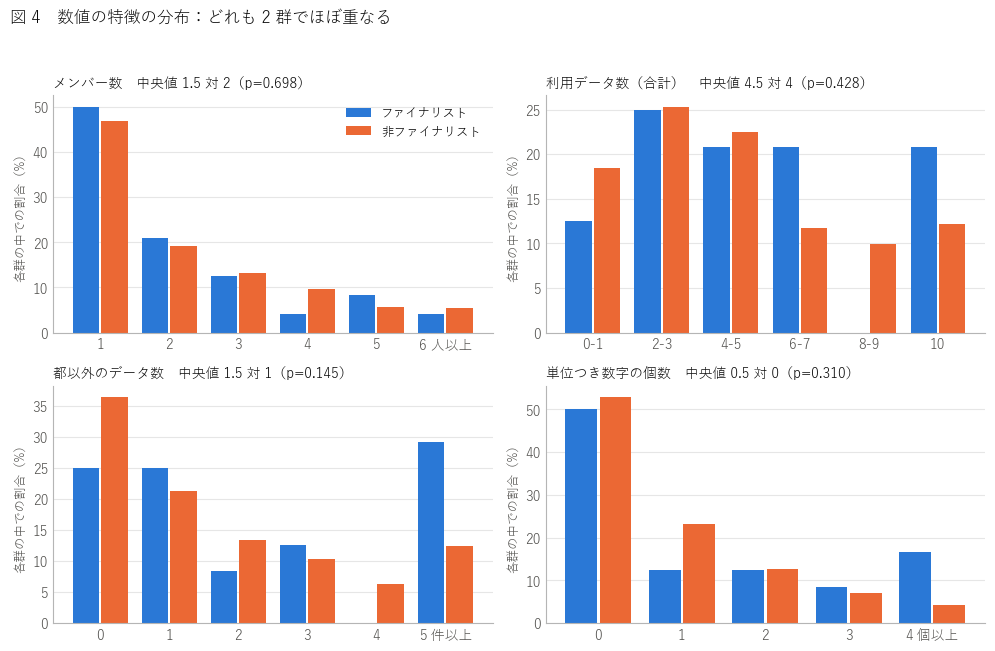

In [8]:
# 図 4: 数値の特徴の分布（各群の中での割合）
items = [("メンバー数", "member_count", [1, 2, 3, 4, 5, 6], "6 人以上"), ("利用データ数（合計）", "n_data_total", [0, 2, 4, 6, 8, 10], None),
         ("都以外のデータ数", "n_data_external", [0, 1, 2, 3, 4, 5], "5 件以上"), ("単位つき数字の個数", "desc_num_count", [0, 1, 2, 3, 4], "4 個以上")]
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6))
for ax, (label, col, edges, last) in zip(axes.ravel(), items):
    if col == "n_data_total":
        bins = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9), (10, 99)]; names = ["0-1", "2-3", "4-5", "6-7", "8-9", "10"]
    else:
        bins = [(e, e) for e in edges[:-1]] + [(edges[-1], 999)]; names = [str(e) for e in edges[:-1]] + [last]
    x = np.arange(len(bins)); w = 0.38
    for k, (grp, color, name) in enumerate([(1, BLUE, "ファイナリスト"), (0, ORANGE, "非ファイナリスト")]):
        v = df.loc[y == grp, col]; share = [((v >= a) & (v <= b)).mean() * 100 for a, b in bins]
        ax.bar(x + (k - 0.5) * (w + 0.03), share, w, color=color, label=name)
    r = Tn.set_index("項目").loc[label]
    ax.set_title(f"{label}　中央値 {r['F中央値']:g} 対 {r['N中央値']:g}（p={r['p値']:.3f}）", loc="left", fontsize=10, color=INK)
    ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylabel("各群の中での割合（%）", color=MUTED, fontsize=9); style(ax, "y")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("図 4　数値の特徴の分布：どれも 2 群でほぼ重なる", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95)); save(fig, "fig04_numeric_distributions"); plt.show()

「優越確率」は、ファイナリスト 1 件と非ファイナリスト 1 件を無作為に選んだとき、ファイナリストの値のほうが大きい確率。0.5 なら差が無い。

## 4. 多カテゴリの特徴：並べ替え検定

主テーマ（13 区分）とチーム人数帯（4 区分）について、「区分によって通過率が違う」かを調べる。期待度数が小さいので、カイ二乗統計量の分布を並べ替え（ファイナリストのラベルを 10 万回シャッフル）で求める。

In [9]:
rng = np.random.default_rng(20261121)


def perm_chi2(col, n_perm=100_000):
    codes = pd.Categorical(df[col]).codes; k = codes.max() + 1
    tot = np.bincount(codes, minlength=k); exp = tot * nF / len(df)

    def stat(yy):
        obs = np.bincount(codes[yy == 1], minlength=k)
        return (((obs - exp) ** 2) / exp).sum()

    s0 = stat(y); cnt = 0; yy = y.copy()
    for _ in range(n_perm):
        rng.shuffle(yy); cnt += stat(yy) >= s0
    return s0, (cnt + 1) / (n_perm + 1)


for label, col in [("主テーマ", "theme_primary"), ("チーム人数帯", "team_size_band")]:
    s, p = perm_chi2(col)
    print(f"{label}: カイ二乗統計量 = {s:.2f}、並べ替え p = {p:.3f}")
pd.crosstab(df["theme_primary"], df["is_finalist"]).rename(columns={0: "非ファイナリスト", 1: "ファイナリスト"}).assign(通過率=lambda t: (t["ファイナリスト"] / t.sum(axis=1) * 100).round(1)).sort_values("通過率", ascending=False)

主テーマ: カイ二乗統計量 = 20.34、並べ替え p = 0.050


チーム人数帯: カイ二乗統計量 = 0.23、並べ替え p = 0.970


is_finalist,非ファイナリスト,ファイナリスト,通過率
theme_primary,,,
防犯・安全,7,2,22.2
まちづくり・住まい,14,3,17.6
観光・おでかけ,34,4,10.5
その他,35,3,7.9
環境・暑さ,28,2,6.7
行政・政策,48,3,5.9
教育,25,1,3.8
交通・移動,80,3,3.6
防災,86,3,3.4


保存: reports/figures/fig05_theme_teamsize.png


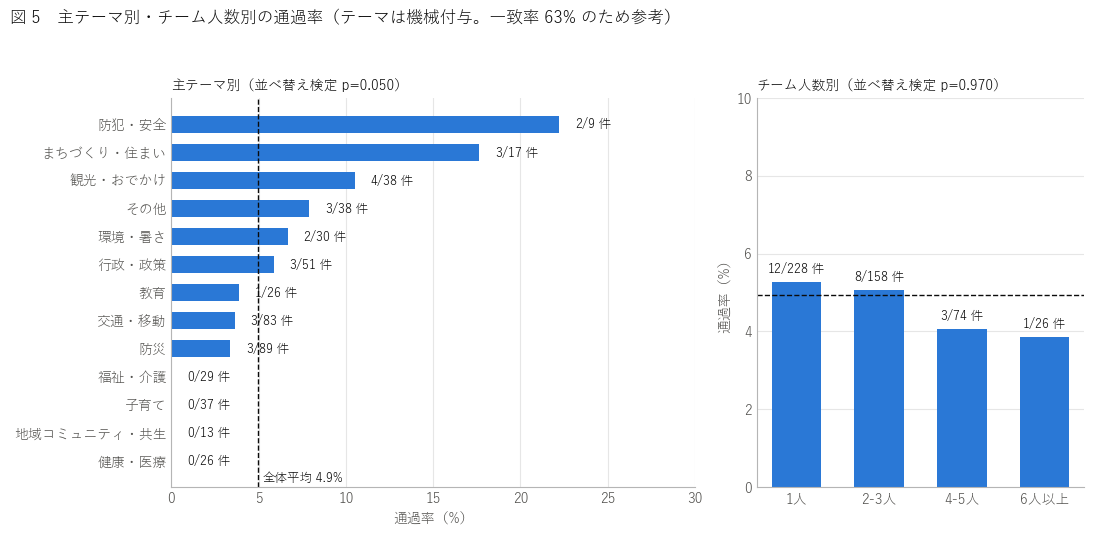

In [10]:
# 図 5: 主テーマ別・人数帯別の通過率
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.4), gridspec_kw={"width_ratios": [1.6, 1]})
t = df.groupby("theme_primary")["is_finalist"].agg(["sum", "count"]); t["rate"] = t["sum"] / t["count"] * 100; t = t.sort_values("rate")
a1.barh(t.index, t["rate"], color=BLUE, height=0.62)
for i, (_, r) in enumerate(t.iterrows()):
    a1.text(r["rate"] + 0.9, i, f"{int(r['sum'])}/{int(r['count'])} 件", va="center", fontsize=9, color=INK)
a1.axvline(nF / len(df) * 100, color=INK, lw=1, ls="--"); a1.text(nF / len(df) * 100 + 0.3, -0.75, "全体平均 4.9%", fontsize=9, color=INK)
a1.set_xlim(0, 30); a1.set_xlabel("通過率（%）", color=MUTED); a1.set_title("主テーマ別（並べ替え検定 p=0.050）", loc="left", fontsize=10, color=INK); style(a1)
order_b = ["1人", "2-3人", "4-5人", "6人以上"]
b = df.groupby("team_size_band")["is_finalist"].agg(["sum", "count"]).loc[order_b]; b["rate"] = b["sum"] / b["count"] * 100
a2.bar(order_b, b["rate"], color=BLUE, width=0.6)
for i, (_, r) in enumerate(b.iterrows()):
    a2.text(i, r["rate"] + 0.25, f"{int(r['sum'])}/{int(r['count'])} 件", ha="center", fontsize=9, color=INK)
a2.axhline(nF / len(df) * 100, color=INK, lw=1, ls="--"); a2.set_ylim(0, 10)
a2.set_ylabel("通過率（%）", color=MUTED); a2.set_title("チーム人数別（並べ替え検定 p=0.970）", loc="left", fontsize=10, color=INK); style(a2, "y")
fig.suptitle("図 5　主テーマ別・チーム人数別の通過率（テーマは機械付与。一致率 63% のため参考）", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94)); save(fig, "fig05_theme_teamsize"); plt.show()

## 5. 検出力：この件数で、どのくらいの差なら見つけられるか

ファイナリストが 24 件しかないので、小さな差は検定で見つけられない。「非ファイナリストでの割合」が 10%・30%・50% の特徴について、ファイナリストでの割合が何 % なら、Fisher の正確検定（両側 5%）で 80% の確率で有意になるかをシミュレーションで求める。

In [11]:
def power(p_n, p_f, n_sim=4000):
    a = rng.binomial(nF, p_f, n_sim); c = rng.binomial(nN, p_n, n_sim); hit = 0; cache = {}
    for ai, ci in zip(a, c):
        if (ai, ci) not in cache:
            cache[(ai, ci)] = stats.fisher_exact([[ai, nF - ai], [ci, nN - ci]])[1] < 0.05
        hit += cache[(ai, ci)]
    return hit / n_sim


rows = []
for p_n in [0.10, 0.30, 0.50]:
    need = next((p_f for p_f in np.arange(p_n, 1.0001, 0.02) if power(p_n, p_f) >= 0.8), np.nan)
    rows.append(dict(非ファイナリストでの割合=f"{p_n:.0%}", 検出に必要なファイナリストでの割合=f"{need:.0%}", 必要なリフト=round(need / p_n, 2)))
pd.DataFrame(rows)

,非ファイナリストでの割合,検出に必要なファイナリストでの割合,必要なリフト
0,10%,32%,3.2
1,30%,60%,2.0
2,50%,80%,1.6


保存: reports/figures/fig06_power.png


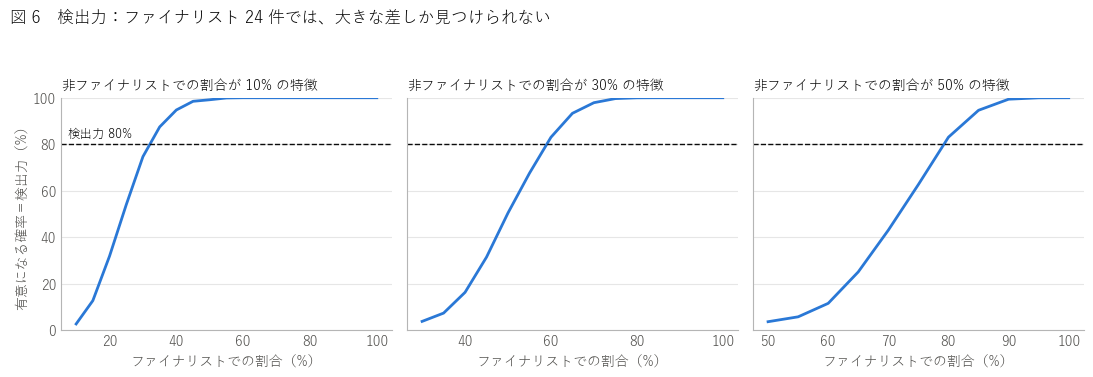

In [12]:
# 図 6: 検出力曲線
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, p_n in zip(axes, [0.10, 0.30, 0.50]):
    xs = np.arange(p_n, 1.0001, 0.05); xs = np.clip(xs, 0, 1); ps = [power(p_n, v, 3000) * 100 for v in xs]
    ax.plot(xs * 100, ps, color=BLUE, lw=2); ax.axhline(80, color=INK, lw=1, ls="--")
    ax.set_title(f"非ファイナリストでの割合が {p_n:.0%} の特徴", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("ファイナリストでの割合（%）", color=MUTED); ax.set_ylim(0, 100); style(ax, "y")
axes[0].set_ylabel("有意になる確率＝検出力（%）", color=MUTED); axes[0].text(axes[0].get_xlim()[0] + 2, 83, "検出力 80%", fontsize=9, color=INK)
fig.suptitle("図 6　検出力：ファイナリスト 24 件では、大きな差しか見つけられない", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92)); save(fig, "fig06_power"); plt.show()

## 6. 多変量：ロジスティック回帰

特徴どうしは重なっている（例：3D を使う作品はシミュレーションもしやすい）。H1・H4・H5・H6 と、人数（H14）を同時に入れて、互いの影響を除いても効果が残るかを見る。ファイナリスト 24 件に対して説明変数は 5 個までに絞った（1 変数あたり約 5 件で、推定は不安定。参考値）。

In [13]:
X_cols = [("データを結合・新指標", "data_combine"), ("デモが独自ドメイン等", "demo_own_domain"), ("3D・AR・PLATEAU", "tech_3d_ar"),
          ("機械学習・最適化・シミュレーション", "tech_ml"), ("1 人チーム", "solo")]
X = np.column_stack([np.ones(len(df))] + [df[c].values for _, c in X_cols]).astype(float)


def nll(b):
    z = X @ b
    return np.sum(np.logaddexp(0, z) - y * z)


res = optimize.minimize(nll, np.zeros(X.shape[1]), method="BFGS")
b = res.x; p_hat = 1 / (1 + np.exp(-(X @ b)))
cov = np.linalg.inv((X * (p_hat * (1 - p_hat))[:, None]).T @ X); se = np.sqrt(np.diag(cov)); z = b / se
ll1 = -nll(b); ll0 = -nll(np.r_[np.log(nF / nN), np.zeros(X.shape[1] - 1)])
lr = 2 * (ll1 - ll0); p_lr = stats.chi2.sf(lr, X.shape[1] - 1)
R = pd.DataFrame(dict(変数=["（切片）"] + [l for l, _ in X_cols], 係数=b.round(3), 調整オッズ比=np.exp(b).round(2),
                      CI下限=np.exp(b - 1.96 * se).round(2), CI上限=np.exp(b + 1.96 * se).round(2), p値=(2 * stats.norm.sf(abs(z))).round(3)))
R.to_csv("data/logistic_regression.csv", index=False, encoding="utf-8-sig")
print(f"尤度比検定（5 変数まとめて効果があるか）: χ² = {lr:.2f}、自由度 5、p = {p_lr:.4f}")
auc = stats.mannwhitneyu(p_hat[y == 1], p_hat[y == 0]).statistic / (nF * nN)
print(f"当てはまり（AUC・学習データ上）: {auc:.3f}")
R

尤度比検定（5 変数まとめて効果があるか）: χ² = 14.18、自由度 5、p = 0.0145
当てはまり（AUC・学習データ上）: 0.683


,変数,係数,調整オッズ比,CI下限,CI上限,p値
0,（切片）,-3.695,0.02,0.01,0.06,0.000
1,データを結合・新指標,0.553,1.74,0.70,4.35,0.236
2,デモが独自ドメイン等,1.215,3.37,1.23,9.26,0.019
3,3D・AR・PLATEAU,1.210,3.35,1.10,10.27,0.034
4,機械学習・最適化・シミュレーション,0.867,2.38,0.75,7.56,0.142
5,1 人チーム,-0.053,0.95,0.40,2.24,0.903


保存: reports/figures/fig07_logistic.png


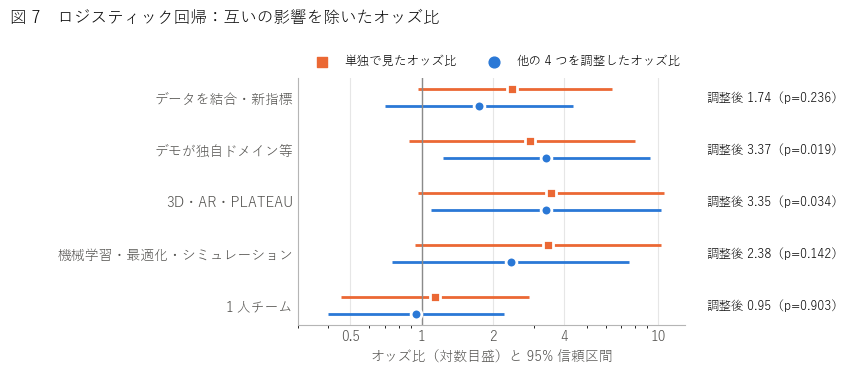

In [14]:
# 図 7: ロジスティック回帰の調整オッズ比と、単独で見たときのオッズ比
Rv = R.iloc[1:].reset_index(drop=True); uni = T.set_index("特徴")
names_map = {"データを結合・新指標": "データを結合・計算して新しい指標を作る", "デモが独自ドメイン等": "デモが独自ドメイン等", "3D・AR・PLATEAU": "3D・AR・PLATEAU",
             "機械学習・最適化・シミュレーション": "機械学習・最適化・シミュレーション", "1 人チーム": "1 人チーム"}
fig, ax = plt.subplots(figsize=(9, 3.8)); yp = np.arange(len(Rv))[::-1]
for yy, (_, r) in zip(yp, Rv.iterrows()):
    u = uni.loc[names_map[r["変数"]]]
    ax.hlines(yy + 0.16, u["CI下限"], u["CI上限"], color=ORANGE, lw=2); ax.scatter(u["オッズ比"], yy + 0.16, s=60, color=ORANGE, marker="s", edgecolor="white", linewidth=2, zorder=3)
    ax.hlines(yy - 0.16, r["CI下限"], r["CI上限"], color=BLUE, lw=2); ax.scatter(r["調整オッズ比"], yy - 0.16, s=60, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
    ax.text(16, yy, f"調整後 {r['調整オッズ比']:.2f}（p={r['p値']:.3f}）", va="center", fontsize=9, color=INK, clip_on=False)
ax.scatter([], [], s=60, color=ORANGE, marker="s", label="単独で見たオッズ比"); ax.scatter([], [], s=60, color=BLUE, label="他の 4 つを調整したオッズ比")
ax.axvline(1, color="#8a8a8a", lw=1); ax.set_xscale("log"); ax.set_xlim(0.3, 13); ax.set_xticks([0.5, 1, 2, 4, 10]); ax.set_xticklabels(["0.5", "1", "2", "4", "10"])
ax.set_yticks(yp); ax.set_yticklabels(Rv["変数"], color=INK); ax.set_xlabel("オッズ比（対数目盛）と 95% 信頼区間", color=MUTED)
fig.suptitle("図 7　ロジスティック回帰：互いの影響を除いたオッズ比", x=0.01, ha="left", color=INK, fontsize=12)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9); style(ax)
fig.subplots_adjust(left=0.33, right=0.76, bottom=0.15, top=0.8); save(fig, "fig07_logistic"); plt.show()

## 7. 合成スコア：勝ち筋の特徴をいくつ持つか

H1・H4・H5・H6 の 4 つ（データの結合・独自ドメイン・3D・最適化やシミュレーション）のうち、いくつ当てはまるかを数える。数が増えるほど通過率が上がるかを、Cochran-Armitage の傾向検定に相当する並べ替え検定で調べる。

**注意**：この 4 つは、§2 で結果が良かった特徴を選んで組み合わせたものである。同じデータで選んで同じデータで検定しているので、ここの p 値は実際より小さく出る（過大評価）。別の年度のデータで確かめるまでは、仮説として扱う。

In [15]:
df["score"] = df[["data_combine", "demo_own_domain", "tech_3d_ar", "tech_ml"]].sum(axis=1)
tab = df.groupby("score")["is_finalist"].agg(作品数="count", ファイナリスト="sum")
tab["通過率"] = (tab["ファイナリスト"] / tab["作品数"] * 100).round(1).astype(str) + "%"
s = df["score"].values; obs = (s * y).sum(); yy = y.copy(); cnt = 0; n_perm = 100_000
for _ in range(n_perm):
    rng.shuffle(yy); cnt += (s * yy).sum() >= obs
print(f"傾向の並べ替え検定（片側）: p = {(cnt + 1) / (n_perm + 1):.5f}")
rho, p_s = stats.spearmanr(s, y)
print(f"Spearman の順位相関: ρ = {rho:.3f}、p = {p_s:.4f}")
tab

傾向の並べ替え検定（片側）: p = 0.00025
Spearman の順位相関: ρ = 0.138、p = 0.0023


,作品数,ファイナリスト,通過率
score,,,
0,238,7,2.9%
1,174,7,4.0%
2,63,6,9.5%
3,11,4,36.4%


保存: reports/figures/fig08_score_trend.png


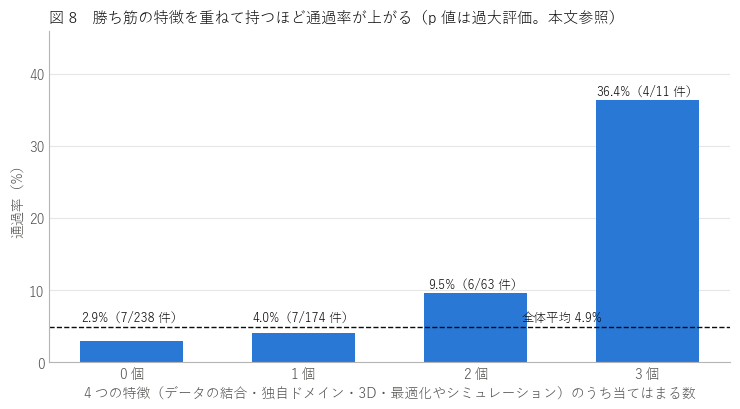

In [16]:
# 図 8: 勝ち筋の特徴を持つ個数と通過率
fig, ax = plt.subplots(figsize=(7.5, 4.2))
rate = tab["ファイナリスト"] / tab["作品数"] * 100
ax.bar([f"{k} 個" for k in tab.index], rate, color=BLUE, width=0.6)
for i, (k, r) in enumerate(tab.iterrows()):
    ax.text(i, max(rate.iloc[i], nF / len(df) * 100) + 0.8, f"{rate.iloc[i]:.1f}%（{int(r['ファイナリスト'])}/{int(r['作品数'])} 件）", ha="center", fontsize=9, color=INK)
ax.axhline(nF / len(df) * 100, color=INK, lw=1, ls="--"); ax.text(2.5, nF / len(df) * 100 + 0.8, "全体平均 4.9%", fontsize=9, color=INK, ha="center")
ax.set_ylim(0, 46); ax.set_ylabel("通過率（%）", color=MUTED)
ax.set_xlabel("4 つの特徴（データの結合・独自ドメイン・3D・最適化やシミュレーション）のうち当てはまる数", color=MUTED)
ax.set_title("図 8　勝ち筋の特徴を重ねて持つほど通過率が上がる（p 値は過大評価。本文参照）", loc="left", color=INK, fontsize=11)
style(ax, "y"); fig.tight_layout(); save(fig, "fig08_score_trend"); plt.show()

## 8. 頑健性の確認：手動コーディングで同じ向きになるか

機械付与は「データの使い方」「課題の具体性」「特定の対象者」で読み違いがある（一致率 65〜77%）。ファイナリスト 24 件と、無作為に選んだ対照群 24 件について、本文を読んで手で付けた値で同じ検定を行い、向きが変わらないかを確かめる。

In [17]:
m = pd.read_csv("data/manual_coding.csv", dtype={"id": str})
g = (m["group"] == "finalist").astype(int).values
checks = [("データを結合・新指標（手動）", (m["manual_data_use_level"] == 3).astype(int)),
          ("データを表示するだけ（手動）", (m["manual_data_use_level"] == 1).astype(int)),
          ("課題の具体性 3（手動）", (m["manual_problem_specificity"] == 3).astype(int)),
          ("課題の具体性 1（手動）", (m["manual_problem_specificity"] == 1).astype(int)),
          ("特定の対象者あり（手動）", m["manual_user_specific"]),
          ("AI が機能として動く（手動）", m["manual_ai_in_product"]),
          ("地図・GIS（手動）", m["manual_tech_map"])]
rows = []
for label, x in checks:
    x = x.values
    a, b = int(((x == 1) & (g == 1)).sum()), int(((x == 0) & (g == 1)).sum())
    c, d = int(((x == 1) & (g == 0)).sum()), int(((x == 0) & (g == 0)).sum())
    rows.append(dict(特徴=label, ファイナリスト=f"{a}/24", 対照群=f"{c}/24", オッズ比=round(odds_ratio([[a, b], [c, d]]).statistic, 2),
                     p値=round(stats.fisher_exact([[a, b], [c, d]])[1], 3)))
Tm = pd.DataFrame(rows); Tm.to_csv("data/hypothesis_tests_manual.csv", index=False, encoding="utf-8-sig"); Tm

,特徴,ファイナリスト,対照群,オッズ比,p値
0,データを結合・新指標（手動）,16/24,11/24,2.32,0.244
1,データを表示するだけ（手動）,2/24,4/24,0.46,0.666
2,課題の具体性 3（手動）,6/24,3/24,2.29,0.461
3,課題の具体性 1（手動）,5/24,5/24,1.00,1.000
4,特定の対象者あり（手動）,12/24,6/24,2.93,0.135
5,AI が機能として動く（手動）,13/24,11/24,1.39,0.773
6,地図・GIS（手動）,11/24,10/24,1.18,1.000


保存: reports/figures/fig09_manual_coding.png


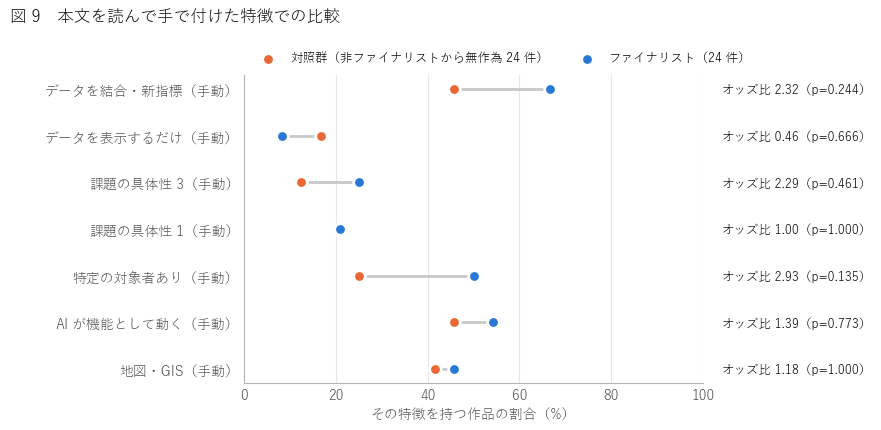

In [18]:
# 図 9: 手動コーディング（48 件）での割合
fig, ax = plt.subplots(figsize=(9, 4.4)); yp = np.arange(len(Tm))[::-1]
fa = Tm["ファイナリスト"].str.split("/").str[0].astype(int) / 24 * 100; ca = Tm["対照群"].str.split("/").str[0].astype(int) / 24 * 100
ax.hlines(yp, ca, fa, color="#c9c9c9", lw=2, zorder=1)
ax.scatter(ca, yp, s=70, color=ORANGE, edgecolor="white", linewidth=2, zorder=3, label="対照群（非ファイナリストから無作為 24 件）")
ax.scatter(fa, yp, s=70, color=BLUE, edgecolor="white", linewidth=2, zorder=3, label="ファイナリスト（24 件）")
for yy, (_, r) in zip(yp, Tm.iterrows()):
    ax.text(104, yy, f"オッズ比 {r['オッズ比']:.2f}（p={r['p値']:.3f}）", va="center", fontsize=9, color=INK, clip_on=False)
ax.set_yticks(yp); ax.set_yticklabels(Tm["特徴"], color=INK); ax.set_xlim(0, 100); ax.set_xlabel("その特徴を持つ作品の割合（%）", color=MUTED)
fig.suptitle("図 9　本文を読んで手で付けた特徴での比較", x=0.01, ha="left", color=INK, fontsize=12)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9); style(ax)
fig.subplots_adjust(left=0.27, right=0.78, bottom=0.13, top=0.83); save(fig, "fig09_manual_coding"); plt.show()

## 8.5 デモ（モック）の確認結果と、コーディングの一致率

ファイナリスト 24 件と対照群 24 件のデモを開いて確認した結果を、Fisher の正確検定で比べる。件数が 24 対 24 と少ないので参考値。

保存: reports/figures/fig10_mock_agreement.png


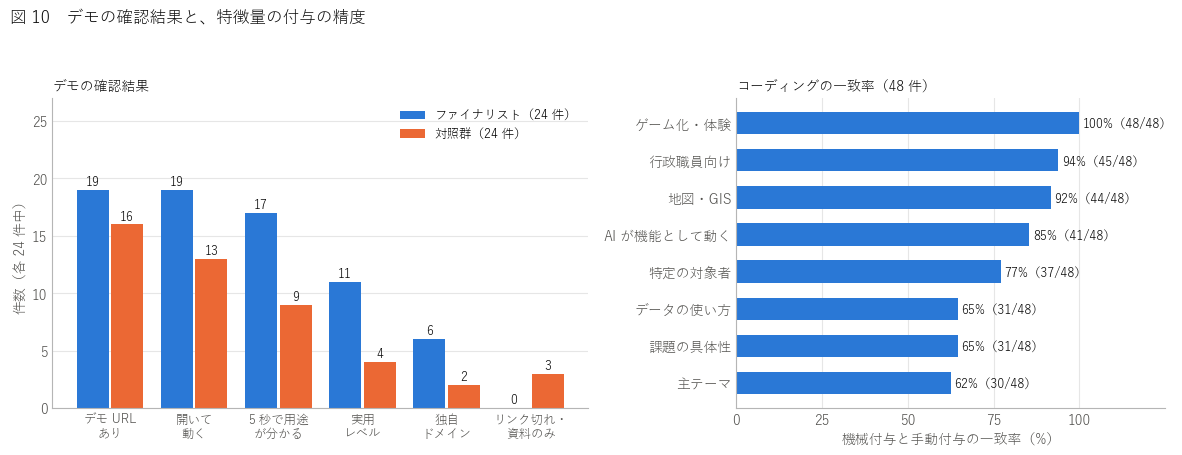

,項目,ファイナリスト,対照群,p値
0,デモ URL あり,19/24,16/24,0.517
1,開いて動く,19/24,13/24,0.125
2,5 秒で用途が分かる,17/24,9/24,0.041
3,実用レベル,11/24,4/24,0.060
4,独自ドメイン,6/24,2/24,0.245
5,リンク切れ・資料のみ,0/24,3/24,0.234


In [19]:
# 図 10: デモ（モック）の確認結果と、機械付与と手動付与の一致率
mk = pd.read_csv("data/mock_summary.csv", dtype={"id": str})
items = [("デモ URL あり", mk["status"] != "デモURLなし"), ("開いて動く", mk["status"] == "動く"), ("5 秒で用途が分かる", mk["clear_in_5s"].str.startswith("はい")),
         ("実用レベル", mk["maturity"] == "実用レベル"), ("独自ドメイン", mk["note"].str.contains("独自ドメイン")), ("リンク切れ・資料のみ", mk["status"].str.startswith(("リンク切れ", "資料")))]
rows_m = []
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
x = np.arange(len(items)); w = 0.38
for k, (grp, color, name) in enumerate([("finalist", BLUE, "ファイナリスト（24 件）"), ("control", ORANGE, "対照群（24 件）")]):
    v = [int(cond[mk["group"] == grp].sum()) for _, cond in items]
    a1.bar(x + (k - 0.5) * (w + 0.03), v, w, color=color, label=name)
    for xi, vi in zip(x, v):
        a1.text(xi + (k - 0.5) * (w + 0.03), vi + 0.4, str(vi), ha="center", fontsize=9, color=INK)
for label, cond in items:
    a_, c_ = int(cond[mk["group"] == "finalist"].sum()), int(cond[mk["group"] == "control"].sum())
    rows_m.append(dict(項目=label, ファイナリスト=f"{a_}/24", 対照群=f"{c_}/24", p値=round(stats.fisher_exact([[a_, 24 - a_], [c_, 24 - c_]])[1], 3)))
a1.set_xticks(x); a1.set_xticklabels(["デモ URL"+NL+"あり", "開いて"+NL+"動く", "5 秒で用途"+NL+"が分かる", "実用"+NL+"レベル", "独自"+NL+"ドメイン", "リンク切れ・"+NL+"資料のみ"], fontsize=9); a1.set_ylim(0, 27); a1.set_ylabel("件数（各 24 件中）", color=MUTED)
a1.set_title("デモの確認結果", loc="left", fontsize=10, color=INK); a1.legend(frameon=False, fontsize=9, loc="upper right"); style(a1, "y")
ag = pd.read_json("data/agreement.json").T
lab = {"theme_primary": "主テーマ", "user_specific": "特定の対象者", "user_gov": "行政職員向け", "problem_specificity": "課題の具体性", "data_use_level": "データの使い方",
       "ai_in_product": "AI が機能として動く", "tech_map": "地図・GIS", "sol_ゲーム化・体験": "ゲーム化・体験"}
ag = ag.assign(rate=ag["all_rate"].astype(float) * 100, name=[lab[i] for i in ag.index]).sort_values("rate")
a2.barh(ag["name"], ag["rate"], color=BLUE, height=0.6)
for i, (_, r) in enumerate(ag.iterrows()):
    a2.text(r["rate"] + 1, i, f"{r['rate']:.0f}%（{r['all']}）", va="center", fontsize=9, color=INK)
a2.set_xlim(0, 125); a2.set_xticks([0, 25, 50, 75, 100]); a2.set_xlabel("機械付与と手動付与の一致率（%）", color=MUTED)
a2.set_title("コーディングの一致率（48 件）", loc="left", fontsize=10, color=INK); style(a2)
fig.suptitle("図 10　デモの確認結果と、特徴量の付与の精度", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93)); save(fig, "fig10_mock_agreement"); plt.show()
Tk = pd.DataFrame(rows_m); Tk.to_csv("data/hypothesis_tests_mock.csv", index=False, encoding="utf-8-sig"); Tk

## 9. まとめ

- 16 個の仮説のうち、補正前に有意（p < 0.05）になったものと、Holm 補正後も有意なものは、下のセルの出力のとおり
- 検出力の計算（§5）が示すように、この件数では **リフトが 2〜3 倍以上ある大きな差しか検定で拾えない**。「有意でない」は「差が無い」という意味ではなく、「この件数では差があるとは言えない」という意味である
- 個々の特徴では弱くても、勝ち筋の特徴を重ねて持つ作品ほど通過率が上がる傾向（§7）が見える。ただし特徴の選び方が結果を見たあとなので、p 値は過大評価であり、別の年度での確認が要る
- 機械付与と手動付与で向きが逆になった特徴がある（特定の対象者：機械ではオッズ比 1 未満、手動では 1 超）。この特徴については結論を出さない

In [20]:
print("補正前に有意（p < 0.05）:", "、".join(f"{r.仮説} {r.特徴}（p={r.p値:.3f}）" for r in T[T["p値"] < 0.05].itertuples()) or "なし")
print("Holm 補正後も有意:", "、".join(f"{r.仮説} {r.特徴}" for r in T[T["p_Holm"] < 0.05].itertuples()) or "なし")
print("BH 補正後に有意（FDR 5%）:", "、".join(f"{r.仮説} {r.特徴}" for r in T[T["p_BH"] < 0.05].itertuples()) or "なし")
print("予想と向きが逆だった仮説:", "、".join(f"{r.仮説} {r.特徴}（オッズ比 {r.オッズ比:.2f}）" for r in T[T["予想と一致"] == "×"].itertuples()) or "なし")

補正前に有意（p < 0.05）: H4 デモが独自ドメイン等（p=0.039）、H5 3D・AR・PLATEAU（p=0.028）、H6 機械学習・最適化・シミュレーション（p=0.032）
Holm 補正後も有意: なし
BH 補正後に有意（FDR 5%）: なし
予想と向きが逆だった仮説: H8 地図・GIS（オッズ比 0.76）、H9 特定の対象者あり（オッズ比 0.66）、H13 都のデータ 0 件（オッズ比 1.24）、H14 1 人チーム（オッズ比 1.14）
